In [1]:
# ============================================================
# Medicine Recommendation System
# Cell 1: Imports & configuration
# ============================================================

import os
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB

warnings.filterwarnings("ignore")

# Plot styling
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

# Project paths
DATA_DIR = "data"
MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

# File names exactly as they appear in your folder
expected_files = [
    "Training.csv", "symptoms_df.csv", "precautions_df.csv",
    "medications.csv", "diets.csv", "workout_df.csv",
    "description.csv", "Symptoms-severity.csv",
]

print(f"Current working folder: {os.getcwd()}\n")
print("Checking dataset files in './data' ...\n")
for f in expected_files:
    path = os.path.join(DATA_DIR, f)
    status = "✅ found" if os.path.exists(path) else "❌ MISSING"
    print(f"{status:12} {f}")

print("\nLibraries loaded successfully.")

Current working folder: C:\Users\Haris\medicine-recommender

Checking dataset files in './data' ...

✅ found      Training.csv
✅ found      symptoms_df.csv
✅ found      precautions_df.csv
✅ found      medications.csv
✅ found      diets.csv
✅ found      workout_df.csv
✅ found      description.csv
✅ found      Symptoms-severity.csv

Libraries loaded successfully.


In [2]:
# ============================================================
# Cell 2: Load all datasets & first look
# ============================================================

from IPython.display import display

files = {
    "training":    "Training.csv",
    "symptoms":    "symptoms_df.csv",
    "precautions": "precautions_df.csv",
    "medications": "medications.csv",
    "diets":       "diets.csv",
    "workout":     "workout_df.csv",
    "description": "description.csv",
    "severity":    "Symptoms-severity.csv",
}

dfs = {name: pd.read_csv(os.path.join(DATA_DIR, fname)) for name, fname in files.items()}

for name, df in dfs.items():
    print("=" * 70)
    print(f"{name.upper()}  ->  {files[name]}")
    print(f"Shape: {df.shape}")
    print(f"Columns: {list(df.columns)[:8]}{' ...' if df.shape[1] > 8 else ''}")
    display(df.head(3))

# Key facts about the main training table
train = dfs["training"]
print("=" * 70)
print("TRAINING TABLE SUMMARY")
print("Rows:", train.shape[0])
print("Symptom columns:", train.shape[1] - 1)
print("Unique diseases:", train["prognosis"].nunique())
print("Missing values:", int(train.isnull().sum().sum()))
print("Duplicate rows:", int(train.duplicated().sum()))

TRAINING  ->  Training.csv
Shape: (4920, 133)
Columns: ['itching', 'skin_rash', 'nodal_skin_eruptions', 'continuous_sneezing', 'shivering', 'chills', 'joint_pain', 'stomach_pain'] ...


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


SYMPTOMS  ->  symptoms_df.csv
Shape: (4920, 6)
Columns: ['Unnamed: 0', 'Disease', 'Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4']


,Unnamed: 0,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4
0,0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches
1,1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN
2,2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN


PRECAUTIONS  ->  precautions_df.csv
Shape: (41, 6)
Columns: ['Unnamed: 0', 'Disease', 'Precaution_1', 'Precaution_2', 'Precaution_3', 'Precaution_4']


...

DESCRIPTION  ->  description.csv
Shape: (41, 2)
Columns: ['Disease', 'Description']


,Disease,Description
0,Fungal infection,Fungal infection is a common skin condition ca...
1,Allergy,Allergy is an immune system reaction to a subs...
2,GERD,GERD (Gastroesophageal Reflux Disease) is a di...


SEVERITY  ->  Symptoms-severity.csv
Shape: (133, 2)
Columns: ['Symptom', 'weight']


,Symptom,weight
0,itching,1
1,skin_rash,3
2,nodal_skin_eruptions,4


TRAINING TABLE SUMMARY
Rows: 4920
Symptom columns: 132
Unique diseases: 41
Missing values: 0
Duplicate rows: 4616


Diseases: 41
Rows per disease -> min: 120, max: 120

Rows before removing duplicates: 4920
Rows after removing duplicates : 304
Unique patterns per disease -> min: 5, max: 10, mean: 7.4

Rows with identical symptoms but different disease labels: 0

Symptoms per row -> min: 3, max: 17, mean: 7.6


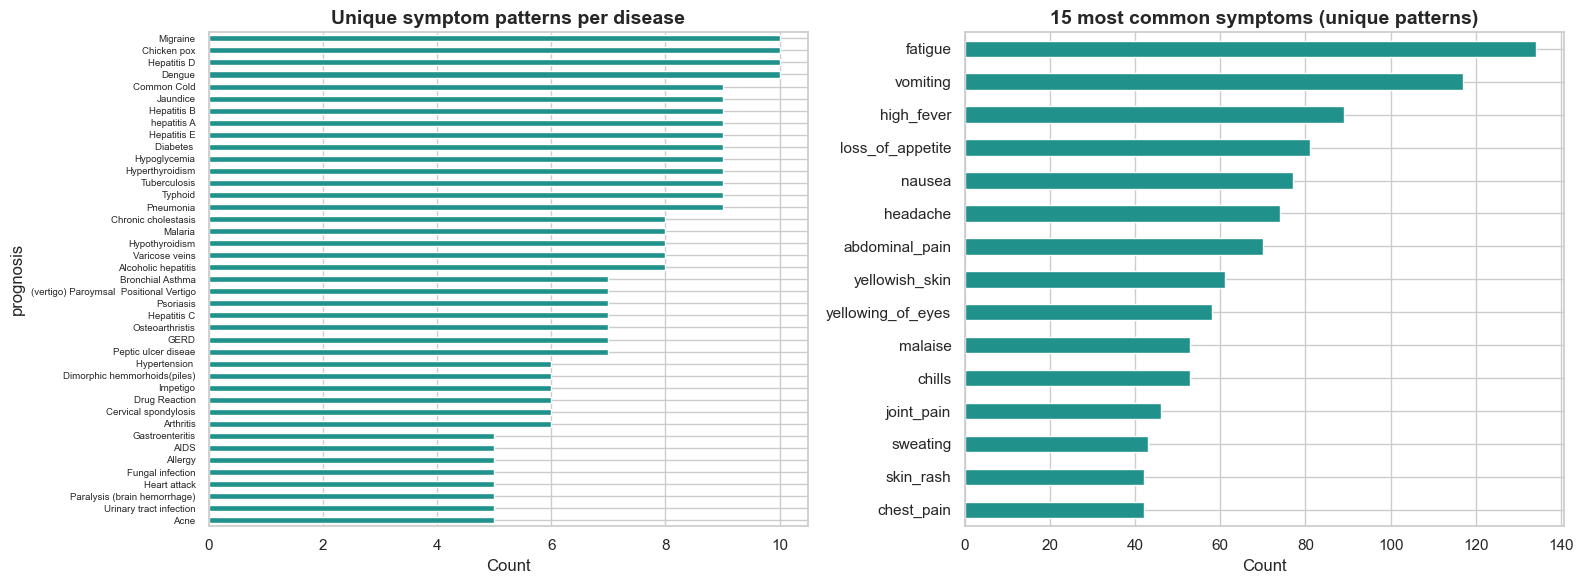

In [3]:
# ============================================================
# Cell 3: Understand duplicates & class balance
# ============================================================

X_cols = [c for c in train.columns if c != "prognosis"]

# 1) Class balance
class_counts = train["prognosis"].value_counts()
print(f"Diseases: {class_counts.shape[0]}")
print(f"Rows per disease -> min: {class_counts.min()}, max: {class_counts.max()}\n")

# 2) Unique patterns overall and per disease
train_unique = train.drop_duplicates().reset_index(drop=True)
print(f"Rows before removing duplicates: {len(train)}")
print(f"Rows after removing duplicates : {len(train_unique)}")
per_disease = train_unique["prognosis"].value_counts()
print(f"Unique patterns per disease -> min: {per_disease.min()}, max: {per_disease.max()}, mean: {per_disease.mean():.1f}\n")

# 3) Conflicts: same symptom pattern labelled with different diseases
conflicts = train_unique.duplicated(subset=X_cols, keep=False).sum()
print(f"Rows with identical symptoms but different disease labels: {conflicts}\n")

# 4) Symptoms per row
symptoms_per_row = train_unique[X_cols].sum(axis=1)
print(f"Symptoms per row -> min: {symptoms_per_row.min()}, max: {symptoms_per_row.max()}, mean: {symptoms_per_row.mean():.1f}")

# 5) Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

per_disease.sort_values().plot(kind="barh", ax=axes[0], color=sns.color_palette("viridis", 1)[0])
axes[0].set_title("Unique symptom patterns per disease")
axes[0].set_xlabel("Count")
axes[0].tick_params(axis="y", labelsize=7)

top = train_unique[X_cols].sum().sort_values(ascending=False).head(15)
top.sort_values().plot(kind="barh", ax=axes[1], color=sns.color_palette("viridis", 1)[0])
axes[1].set_title("15 most common symptoms (unique patterns)")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()

In [4]:
# ============================================================
# Cell 4: Clean data, validate names, build lookup dictionaries
# ============================================================
import ast

# ---------- 1) Training data: single source of truth for symptoms ----------
train = dfs["training"].copy()
train.columns = train.columns.str.strip()
train["prognosis"] = train["prognosis"].str.strip()

SYMPTOMS = [c for c in train.columns if c != "prognosis"]
train_unique = train.drop_duplicates().reset_index(drop=True)
print(f"Symptoms: {len(SYMPTOMS)} | Unique training rows: {len(train_unique)}")

# ---------- 2) Severity file vs training columns ----------
sev = dfs["severity"].copy()
sev["Symptom"] = sev["Symptom"].str.strip()
only_in_severity = set(sev["Symptom"]) - set(SYMPTOMS)
only_in_training = set(SYMPTOMS) - set(sev["Symptom"])
print(f"\nIn severity file but not in training: {only_in_severity}")
print(f"In training but not in severity file: {only_in_training}")

# ---------- 3) Clean the info tables ----------
desc = dfs["description"].copy()
prec = dfs["precautions"].drop(columns=["Unnamed: 0"], errors="ignore").copy()
meds = dfs["medications"].copy()
diet = dfs["diets"].copy()
work = dfs["workout"].drop(columns=["Unnamed: 0.1", "Unnamed: 0"], errors="ignore").copy()
work = work.rename(columns={"disease": "Disease"})

for d in (desc, prec, meds, diet, work):
    d["Disease"] = d["Disease"].astype(str).str.strip()

# ---------- 4) Validate disease names match everywhere ----------
reference = set(train["prognosis"].unique())
print("\nDisease name check against Training.csv:")
all_ok = True
for name, d in [("description", desc), ("precautions", prec), ("medications", meds),
                ("diets", diet), ("workout", work)]:
    names = set(d["Disease"].unique())
    missing, extra = reference - names, names - reference
    ok = not missing and not extra
    all_ok &= ok
    print(f"  {'✅' if ok else '❌'} {name:12} missing={missing or '-'} extra={extra or '-'}")

# ---------- 5) Convert to clean Python structures ----------
def parse_list(x):
    try:
        return [str(i).strip() for i in ast.literal_eval(x)]
    except Exception:
        return [str(x).strip()]

description_map = dict(zip(desc["Disease"], desc["Description"].str.strip()))

precaution_cols = [c for c in prec.columns if c.startswith("Precaution")]
precaution_map = {
    row["Disease"]: [str(row[c]).strip().capitalize() for c in precaution_cols if pd.notna(row[c])]
    for _, row in prec.iterrows()
}

medication_map = {r["Disease"]: parse_list(r["Medication"]) for _, r in meds.iterrows()}
diet_map       = {r["Disease"]: parse_list(r["Diet"]) for _, r in diet.iterrows()}
workout_map    = work.groupby("Disease")["workout"].apply(lambda s: [str(x).strip() for x in s]).to_dict()

severity_map = dict(zip(sev["Symptom"], sev["weight"]))

# ---------- 6) Sanity check with one disease ----------
sample = "Fungal infection"
print(f"\n--- Sample lookup: {sample} ---")
print("Description :", description_map[sample][:120], "...")
print("Precautions :", precaution_map[sample])
print("Medications :", medication_map[sample])
print("Diet        :", diet_map[sample])
print("Workout     :", workout_map[sample][:4], "...")
print(f"\nAll disease names consistent: {all_ok}")

Symptoms: 132 | Unique training rows: 304

In severity file but not in training: {'spotting_urination', 'prognosis', 'dischromic_patches', 'foul_smell_ofurine'}
In training but not in severity file: {'fluid_overload.1', 'dischromic _patches', 'foul_smell_of urine', 'spotting_ urination'}

Disease name check against Training.csv:
  ❌ description  missing={'Peptic ulcer diseae', '(vertigo) Paroymsal  Positional Vertigo'} extra={'Peptic ulcer disease', '(vertigo) Paroymsal Positional Vertigo'}
  ✅ precautions  missing=- extra=-
  ❌ medications  missing={'Peptic ulcer diseae', '(vertigo) Paroymsal  Positional Vertigo'} extra={'Peptic ulcer disease', '(vertigo) Paroymsal Positional Vertigo'}
  ❌ diets        missing={'Peptic ulcer diseae', '(vertigo) Paroymsal  Positional Vertigo'} extra={'Peptic ulcer disease', '(vertigo) Paroymsal Positional Vertigo'}
  ❌ workout      missing={'Peptic ulcer diseae'} extra={'Peptic ulcer disease'}

--- Sample lookup: Fungal infection ---
Description : Fung

In [5]:
# ============================================================
# Cell 4b: Fix name typos, drop duplicate column, re-validate
# ============================================================

# ---------- 1) Disease name fixes (applied everywhere) ----------
DISEASE_FIX = {
    "Peptic ulcer diseae": "Peptic ulcer disease",
    "(vertigo) Paroymsal  Positional Vertigo": "(vertigo) Paroymsal Positional Vertigo",
}
train["prognosis"] = train["prognosis"].replace(DISEASE_FIX)
precaution_map = {DISEASE_FIX.get(k, k): v for k, v in precaution_map.items()}

# ---------- 2) Symptom name fixes (match the severity file) ----------
SYMPTOM_FIX = {
    "dischromic _patches": "dischromic_patches",
    "foul_smell_of urine": "foul_smell_ofurine",
    "spotting_ urination": "spotting_urination",
}
train = train.rename(columns=SYMPTOM_FIX)

# ---------- 3) Duplicate 'fluid_overload' column ----------
if "fluid_overload.1" in train.columns:
    same = train["fluid_overload"].equals(train["fluid_overload.1"])
    print(f"fluid_overload and fluid_overload.1 identical: {same}")
    if not same:
        print("Differences in", int((train['fluid_overload'] != train['fluid_overload.1']).sum()), "rows -> merging with OR")
        train["fluid_overload"] = (train["fluid_overload"] | train["fluid_overload.1"]).astype(int)
    train = train.drop(columns=["fluid_overload.1"])

# ---------- 4) Rebuild the core variables ----------
SYMPTOMS = [c for c in train.columns if c != "prognosis"]
train_unique = train.drop_duplicates().reset_index(drop=True)
conflicts = train_unique.duplicated(subset=SYMPTOMS, keep=False).sum()
print(f"\nSymptoms: {len(SYMPTOMS)} | Unique rows: {len(train_unique)} | Conflicting rows: {conflicts}")

# ---------- 5) Re-validate symptoms vs severity ----------
sev = sev[sev["Symptom"] != "prognosis"]
severity_map = dict(zip(sev["Symptom"], sev["weight"]))
print("In training but not in severity:", set(SYMPTOMS) - set(severity_map) or "-")
print("In severity but not in training:", set(severity_map) - set(SYMPTOMS) or "-")

# ---------- 6) Re-validate disease names across ALL lookup tables ----------
reference = set(train["prognosis"].unique())
maps = {"description": description_map, "precautions": precaution_map,
        "medications": medication_map, "diets": diet_map, "workout": workout_map}

print(f"\nDiseases in training: {len(reference)}")
all_ok = True
for name, m in maps.items():
    missing, extra = reference - set(m), set(m) - reference
    ok = not missing and not extra
    all_ok &= ok
    print(f"  {'✅' if ok else '❌'} {name:12} missing={missing or '-'} extra={extra or '-'}")

print(f"\nEverything consistent: {all_ok}")

fluid_overload and fluid_overload.1 identical: False
Differences in 114 rows -> merging with OR

Symptoms: 131 | Unique rows: 304 | Conflicting rows: 0
In training but not in severity: -
In severity but not in training: -

Diseases in training: 41
  ✅ description  missing=- extra=-
  ✅ precautions  missing=- extra=-
  ✅ medications  missing=- extra=-
  ✅ diets        missing=- extra=-
  ❌ workout      missing={'(vertigo) Paroymsal Positional Vertigo'} extra={'(vertigo) Paroymsal  Positional Vertigo'}

Everything consistent: False


In [6]:
# ============================================================
# Cell 4c: Fix workout_map key & final validation
# ============================================================

workout_map = {DISEASE_FIX.get(k, k): v for k, v in workout_map.items()}

reference = set(train["prognosis"].unique())
maps = {"description": description_map, "precautions": precaution_map,
        "medications": medication_map, "diets": diet_map, "workout": workout_map}

all_ok = True
for name, m in maps.items():
    missing, extra = reference - set(m), set(m) - reference
    ok = not missing and not extra
    all_ok &= ok
    print(f"  {'✅' if ok else '❌'} {name:12} missing={missing or '-'} extra={extra or '-'}")

print(f"\nEverything consistent: {all_ok}")
print(f"Final dataset -> {len(SYMPTOMS)} symptoms, {len(reference)} diseases, {len(train_unique)} unique patterns")

  ✅ description  missing=- extra=-
  ✅ precautions  missing=- extra=-
  ✅ medications  missing=- extra=-
  ✅ diets        missing=- extra=-
  ✅ workout      missing=- extra=-

Everything consistent: True
Final dataset -> 131 symptoms, 41 diseases, 304 unique patterns


X shape: (304, 131) | classes: 41
SVC (linear)         mean=1.0000  std=0.0000  (3.9s)
Logistic Regression  mean=1.0000  std=0.0000  (2.9s)
Random Forest        mean=1.0000  std=0.0000  (3.4s)
Gradient Boosting    mean=0.8058  std=0.0247  (6.1s)
KNN                  mean=1.0000  std=0.0000  (0.1s)
Multinomial NB       mean=0.9769  std=0.0082  (0.1s)

=== Ranking ===


,Model,Mean Accuracy,Std,Min,Max,Time (s)
0,SVC (linear),1.0000,0.0000,1.0000,1.0000,3.900000
1,Logistic Regression,1.0000,0.0000,1.0000,1.0000,2.900000
2,Random Forest,1.0000,0.0000,1.0000,1.0000,3.400000
3,KNN,1.0000,0.0000,1.0000,1.0000,0.100000
4,Multinomial NB,0.9769,0.0082,0.9667,0.9836,0.100000
5,Gradient Boosting,0.8058,0.0247,0.7833,0.8361,6.100000


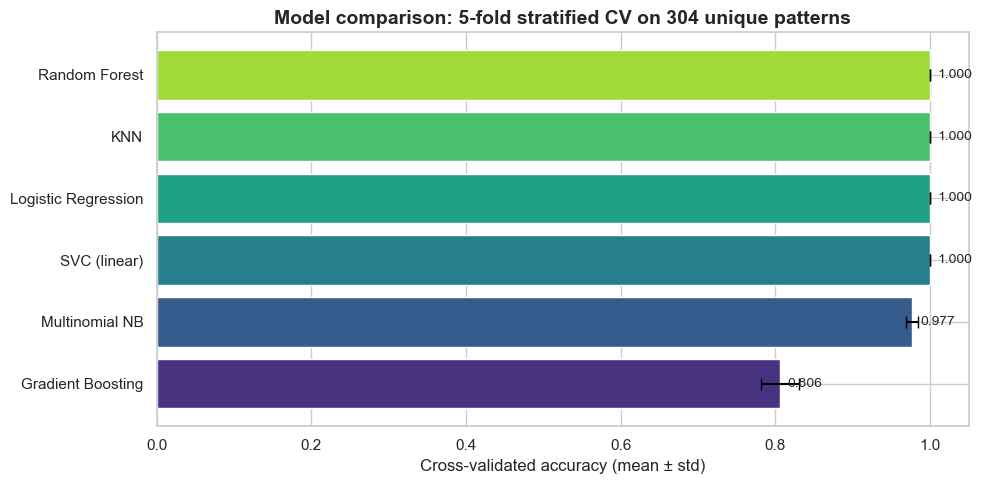

In [7]:
# ============================================================
# Cell 5: Model comparison with stratified cross-validation
# ============================================================
import time
from sklearn.linear_model import LogisticRegression

# ---------- 1) Features and target ----------
X = train_unique[SYMPTOMS].values
le = LabelEncoder()
y = le.fit_transform(train_unique["prognosis"])
print(f"X shape: {X.shape} | classes: {len(le.classes_)}")

# ---------- 2) Candidate models ----------
models = {
    "SVC (linear)":        SVC(kernel="linear", random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=50, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=3),
    "Multinomial NB":      MultinomialNB(),
}

# ---------- 3) 5-fold stratified CV ----------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
    start = time.time()
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    elapsed = time.time() - start
    rows.append({"Model": name, "Mean Accuracy": scores.mean(),
                 "Std": scores.std(), "Min": scores.min(), "Max": scores.max(),
                 "Time (s)": round(elapsed, 1)})
    print(f"{name:20} mean={scores.mean():.4f}  std={scores.std():.4f}  ({elapsed:.1f}s)")

results = pd.DataFrame(rows).sort_values("Mean Accuracy", ascending=False).reset_index(drop=True)
print("\n=== Ranking ===")
display(results.style.format({"Mean Accuracy": "{:.4f}", "Std": "{:.4f}", "Min": "{:.4f}", "Max": "{:.4f}"}))

# ---------- 4) Chart ----------
fig, ax = plt.subplots(figsize=(10, 5))
order = results.sort_values("Mean Accuracy")
ax.barh(order["Model"], order["Mean Accuracy"], xerr=order["Std"],
        color=sns.color_palette("viridis", len(order)), capsize=4)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Cross-validated accuracy (mean ± std)")
ax.set_title("Model comparison: 5-fold stratified CV on 304 unique patterns")
for i, v in enumerate(order["Mean Accuracy"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=10)
plt.tight_layout()
plt.savefig("models/model_comparison.png", dpi=150)
plt.show()

Logistic Regression  done (0.3s)
SVC (linear)         done (0.8s)
Random Forest        done (3.1s)
KNN                  done (0.2s)
Multinomial NB       done (0.2s)

=== Top-1 accuracy by number of symptoms entered ===


Symptoms entered,1,2,3,4,5
Model,,,,,
KNN,0.212,0.435,0.507,0.626,0.747
Logistic Regression,0.328,0.517,0.685,0.808,0.885
Multinomial NB,0.417,0.711,0.871,0.935,0.956
Random Forest,0.404,0.567,0.716,0.805,0.890
SVC (linear),0.198,0.388,0.511,0.618,0.697


=== Top-3 accuracy by number of symptoms entered ===


Symptoms entered,1,2,3,4,5
Model,,,,,
KNN,0.247,0.448,0.533,0.645,0.778
Logistic Regression,0.434,0.639,0.815,0.933,0.974
Multinomial NB,0.658,0.899,0.977,0.990,0.996
Random Forest,0.542,0.777,0.880,0.933,0.963
SVC (linear),0.273,0.479,0.597,0.728,0.826


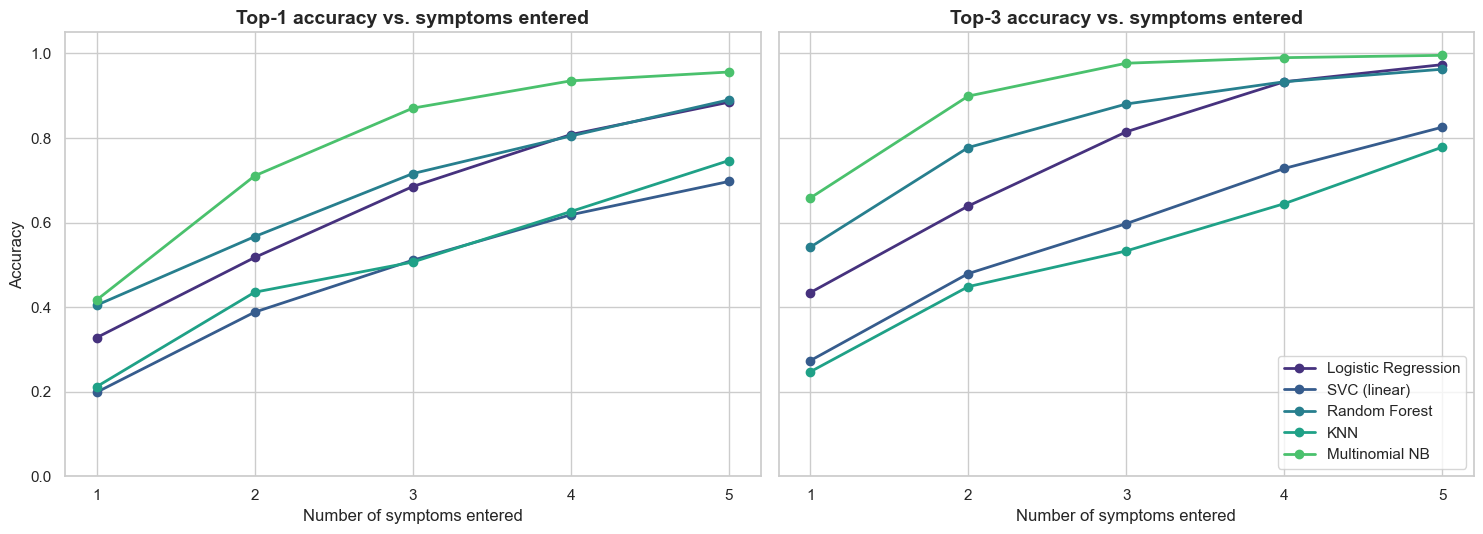

In [8]:
# ============================================================
# Cell 6: Robustness test - users enter only a few symptoms
# ============================================================
from sklearn.base import clone

rng = np.random.default_rng(42)

def mask_row(row, k, rng):
    """Keep only k randomly chosen symptoms from a row."""
    idx = np.flatnonzero(row)
    keep = rng.choice(idx, size=min(k, len(idx)), replace=False)
    out = np.zeros_like(row)
    out[keep] = 1
    return out

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "SVC (linear)":        SVC(kernel="linear", probability=True, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=3),
    "Multinomial NB":      MultinomialNB(),
}

K_LIST = [1, 2, 3, 4, 5]   # number of symptoms the "user" enters
REPEATS = 3                # random masks per fold, to reduce luck
records = []

for name, model in candidates.items():
    start = time.time()
    for tr, te in cv.split(X, y):
        m = clone(model).fit(X[tr], y[tr])
        yt = y[te]
        for k in K_LIST:
            for _ in range(REPEATS):
                Xm = np.array([mask_row(r, k, rng) for r in X[te]])
                proba = m.predict_proba(Xm)
                top3 = m.classes_[np.argsort(proba, axis=1)[:, ::-1][:, :3]]
                records.append({
                    "Model": name, "Symptoms entered": k,
                    "Top-1": (top3[:, 0] == yt).mean(),
                    "Top-3": np.mean([yt[i] in top3[i] for i in range(len(yt))]),
                })
    print(f"{name:20} done ({time.time() - start:.1f}s)")

rob = pd.DataFrame(records).groupby(["Model", "Symptoms entered"]).mean().reset_index()

print("\n=== Top-1 accuracy by number of symptoms entered ===")
display(rob.pivot(index="Model", columns="Symptoms entered", values="Top-1").round(3))
print("=== Top-3 accuracy by number of symptoms entered ===")
display(rob.pivot(index="Model", columns="Symptoms entered", values="Top-3").round(3))

# ---------- Chart ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, metric in zip(axes, ["Top-1", "Top-3"]):
    for name in candidates:
        d = rob[rob["Model"] == name]
        ax.plot(d["Symptoms entered"], d[metric], marker="o", linewidth=2, label=name)
    ax.set_title(f"{metric} accuracy vs. symptoms entered")
    ax.set_xlabel("Number of symptoms entered")
    ax.set_xticks(K_LIST)
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Accuracy")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig("models/robustness_comparison.png", dpi=150)
plt.show()

In [9]:
# ============================================================
# Cell 7: Train final model (Multinomial NB) on ALL data & save
# ============================================================
import json

final_model = MultinomialNB()
final_model.fit(X, y)
print(f"Final model trained on {X.shape[0]} patterns, {X.shape[1]} symptoms, {len(le.classes_)} diseases")

# ---------- Helper: predict top-N from a list of symptom names ----------
def predict_top(symptom_list, top_n=3):
    vec = np.zeros((1, len(SYMPTOMS)))
    unknown = []
    for s in symptom_list:
        s = s.strip().lower().replace(" ", "_")
        if s in SYMPTOMS:
            vec[0, SYMPTOMS.index(s)] = 1
        else:
            unknown.append(s)
    proba = final_model.predict_proba(vec)[0]
    top_idx = np.argsort(proba)[::-1][:top_n]
    return [(le.classes_[i], float(proba[i])) for i in top_idx], unknown

# ---------- Quick sanity tests ----------
tests = [
    ["itching", "skin_rash", "nodal_skin_eruptions"],
    ["high_fever", "headache", "vomiting"],
    ["cough", "breathlessness"],
]
for t in tests:
    result, unknown = predict_top(t)
    print(f"\nSymptoms: {t}")
    for disease, p in result:
        print(f"   {p*100:5.1f}%  {disease}")
    if unknown:
        print("   Unknown symptoms:", unknown)

# ---------- Save artifacts for the web app ----------
joblib.dump(final_model, "models/medicine_model.joblib")
joblib.dump(le, "models/label_encoder.joblib")

with open("models/symptoms.json", "w") as f:
    json.dump(SYMPTOMS, f, indent=2)

lookups = {
    "description": description_map,
    "precautions": precaution_map,
    "medications": medication_map,
    "diets": diet_map,
    "workout": workout_map,
}
with open("models/lookups.json", "w") as f:
    json.dump(lookups, f, indent=2)

print("\nSaved to ./models :", sorted(os.listdir("models")))

Final model trained on 304 patterns, 131 symptoms, 41 diseases

Symptoms: ['itching', 'skin_rash', 'nodal_skin_eruptions']
    45.4%  Fungal infection
    18.5%  Chicken pox
    13.1%  Drug Reaction

Symptoms: ['high_fever', 'headache', 'vomiting']
    26.4%  Typhoid
    24.4%  Malaria
    24.2%  Dengue

Symptoms: ['cough', 'breathlessness']
    30.2%  Pneumonia
    25.1%  Bronchial Asthma
    20.9%  Tuberculosis

Saved to ./models : ['label_encoder.joblib', 'lookups.json', 'medicine_model.joblib', 'model_comparison.png', 'robustness_comparison.png', 'symptoms.json']


In [10]:
# ============================================================
# Cell 8: Reload saved artifacts & build the recommendation function
# ============================================================
import json

# ---------- 1) Load everything from disk (as the web app will) ----------
model = joblib.load("models/medicine_model.joblib")
encoder = joblib.load("models/label_encoder.joblib")
with open("models/symptoms.json") as f:
    symptoms_saved = json.load(f)
with open("models/lookups.json") as f:
    lk = json.load(f)

# ---------- 2) Verify the reload ----------
print("Reloaded model matches in-memory model :", np.allclose(model.predict_proba(X), final_model.predict_proba(X)))
print("Symptom list matches                   :", symptoms_saved == SYMPTOMS)
print("Disease classes match                  :", list(encoder.classes_) == list(le.classes_))
print(f"Accuracy on training patterns (sanity) : {(model.predict(X) == y).mean():.3f}")

# ---------- 3) Recommendation function (uses ONLY the saved files) ----------
def recommend(symptom_list, top_n=3):
    """Return the top-N likely diseases plus full guidance for the best match."""
    clean = [s.strip().lower().replace(" ", "_") for s in symptom_list]
    valid = [s for s in clean if s in symptoms_saved]
    unknown = [s for s in clean if s not in symptoms_saved]
    if not valid:
        return {"error": "No recognised symptoms.", "unknown": unknown}

    vec = np.zeros((1, len(symptoms_saved)))
    for s in valid:
        vec[0, symptoms_saved.index(s)] = 1

    proba = model.predict_proba(vec)[0]
    order = np.argsort(proba)[::-1][:top_n]
    top = [{"disease": encoder.classes_[i], "score": round(float(proba[i]) * 100, 1)} for i in order]

    best = top[0]["disease"]
    return {
        "symptoms_used": valid,
        "unknown": unknown,
        "top_predictions": top,
        "description": lk["description"][best],
        "precautions": lk["precautions"][best],
        "medications": lk["medications"][best],
        "diet": lk["diets"][best],
        "workout": lk["workout"][best],
    }

# ---------- 4) Demo ----------
def show(result):
    if "error" in result:
        print(result["error"], result["unknown"]); return
    print("Symptoms used:", ", ".join(result["symptoms_used"]))
    if result["unknown"]:
        print("Not recognised:", result["unknown"])
    print("\nTop matches:")
    for p in result["top_predictions"]:
        print(f"  {p['score']:5.1f}  {p['disease']}")
    print("\nDescription :", result["description"])
    print("\nPrecautions :", *[f"\n  - {x}" for x in result["precautions"]])
    print("\nMedications :", *[f"\n  - {x}" for x in result["medications"]])
    print("\nDiet        :", *[f"\n  - {x}" for x in result["diet"]])
    print("\nWorkout     :", *[f"\n  - {x}" for x in result["workout"][:5]])

show(recommend(["itching", "skin rash", "nodal skin eruptions", "fever"]))

Reloaded model matches in-memory model : True
Symptom list matches                   : True
Disease classes match                  : True
Accuracy on training patterns (sanity) : 0.977
Symptoms used: itching, skin_rash, nodal_skin_eruptions
Not recognised: ['fever']

Top matches:
   45.4  Fungal infection
   18.5  Chicken pox
   13.1  Drug Reaction

Description : Fungal infection is a common skin condition caused by fungi.

Precautions : 
  - Bath twice 
  - Use detol or neem in bathing water 
  - Keep infected area dry 
  - Use clean cloths

Medications : 
  - Antifungal Cream 
  - Fluconazole 
  - Terbinafine 
  - Clotrimazole 
  - Ketoconazole

Diet        : 
  - Antifungal Diet 
  - Probiotics 
  - Garlic 
  - Coconut oil 
  - Turmeric

Workout     : 
  - Avoid sugary foods 
  - Consume probiotics 
  - Increase intake of garlic 
  - Include yogurt in diet 
  - Limit processed foods


In [11]:
!pip install flask

In [12]:
   import os
   print(os.getcwd())

C:\Users\Haris\medicine-recommender
